# Tumor volume, centroid location, and overall survival (UCSF-PDGM) — revised analysis
Changes from the original notebook (per reviewer/mentor feedback):
- Survival is analyzed with the survival-status column (censoring) using **Kaplan–Meier curves and log-rank tests** (no t-tests/Pearson correlations on OS).
- Levene's test and a power analysis are added to the group comparisons.
- Lasso is refit on **all variables combined** (no univariable screening); scaling and tuning happen inside the cross-validation folds.
- Analyses are run on two cohorts (primary, and QC outliers included) to check whether the exclusions matter.
- Figure 1 = flow chart (panel A) + characteristics table (panel B).

Install once if needed: `pip install lifelines nibabel scikit-learn scipy seaborn matplotlib pandas`

In [15]:
BASE = 'path/to/your/data'

In [1]:
%pip install lifelines nibabel scikit-learn scipy seaborn matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob, os, re, itertools
import numpy as np
import pandas as pd
import nibabel as nib
from scipy import ndimage, stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import lifelines
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
from lifelines.utils import median_survival_times
from lifelines.plotting import add_at_risk_counts

import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import LassoCV
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- Paths and settings (edit if needed) ----
BASE = '/Users/advik/Desktop/MRI for Research'
SAVE_DIR = BASE
METADATA_FILE = 'UCSF-PDGM-metadata_v5.csv'   # clinical data file (in BASE)
EVENT_COL = '1-dead 0-alive'      # survival-status column (1 = dead, 0 = alive/censored)
TABLE_EXTRA_ROWS = False          # True adds diagnosis, IDH, MGMT, extent of resection, prior biopsy rows to Figure 1B
USE_EXTRA_COVARIATES = False      # True adds IDH, MGMT, EOR, prior biopsy to the Lasso (section 6)
RANDOM_SEED = 42
ALPHA = 0.05
os.makedirs(SAVE_DIR, exist_ok=True)

# Package versions (report these in the Methods)
for name, mod in [('numpy', np), ('pandas', pd), ('nibabel', nib), ('scipy', __import__('scipy')),
                  ('scikit-learn', sklearn), ('lifelines', lifelines),
                  ('matplotlib', __import__('matplotlib')), ('seaborn', sns)]:
    print(f'{name}: {mod.__version__}')

numpy: 2.4.6
pandas: 2.3.3
nibabel: 5.4.2
scipy: 1.17.1
scikit-learn: 1.9.0
lifelines: 0.30.3
matplotlib: 3.10.9
seaborn: 0.13.2


## 1. Load participants and QC tables, fix IDs, and track exclusions for the flow chart

In [3]:
data = pd.read_csv(f'{BASE}/{METADATA_FILE}', sep=None, engine='python')   # auto-detects comma vs tab
qc = pd.read_csv(f'{BASE}/qc.tsv', sep='\t')
print('Clinical columns:', list(data.columns))
assert EVENT_COL in data.columns, f"Column '{EVENT_COL}' not found - check the names printed above and edit EVENT_COL"

# Make IDs match the segmentation/QC naming (sub-0004). Handles 'UCSF-PDGM-004', 'UCSF-PDGM-0429_FU003d', 'sub-004', and 'sub-0004'.
def standardize_id(x):
    m = re.search(r'(\d+)(.*)$', str(x))                     # number, then any suffix such as _FU003d
    return f"sub-{int(m.group(1)):04d}{m.group(2)}"
data['ID'] = data['ID'].apply(standardize_id)
data['ID_num'] = data['ID'].str.extract(r'sub-(\d+)')[0]     # numeric part only (used to match segmentation files)
print(f"Participants: {len(data)} | deaths: {int(data[EVENT_COL].sum())} | alive/censored: {int((data[EVENT_COL] == 0).sum())} | missing OS: {int(data['OS'].isna().sum())}")
# The metadata has 501 rows but only 495 unique patients: 6 patients appear twice (e.g. 'UCSF-PDGM-391' and 'UCSF-PDGM-0391_FU016d').
# Verify the repeat rows are true duplicates of an included patient, then drop them (keep the baseline row).
is_repeat = data['ID'].str.contains('_FU')
check_cols = ['Sex', 'Age at MRI', 'WHO CNS Grade', 'OS', EVENT_COL]
for _, r in data[is_repeat].iterrows():
    base_row = data[(data['ID_num'] == r['ID_num']) & ~is_repeat]
    same = (len(base_row) == 1) and all((base_row.iloc[0][c] == r[c]) or (pd.isna(base_row.iloc[0][c]) and pd.isna(r[c])) for c in check_cols)
    print(f"  {r['ID']}: matching baseline row found = {len(base_row) == 1}, identical clinical values = {same}")

flow = {'original': len(data), 'repeat_sessions': int(is_repeat.sum())}
data = data[~is_repeat].copy()
flow['unique_patients'] = len(data)

qc['ID'] = qc['file name'].apply(lambda f: f.split('_dwi')[0])
qc = qc[~qc['ID'].str.contains('_FU')]          # baseline scans only

in_data_not_qc = set(data['ID']) - set(qc['ID'])
flow['missing_qc'] = len(in_data_not_qc)
data_qc = data[~data['ID'].isin(in_data_not_qc)].copy()
flow['after_qc'] = len(data_qc)
outlier_ids = qc.loc[qc['outlier'] == 1, 'ID'].tolist()
print(flow, '| QC outliers flagged:', len(outlier_ids))

Clinical columns: ['ID', 'Sex', 'Age at MRI', 'WHO CNS Grade', 'Final pathologic diagnosis (WHO 2021)', 'MGMT status', 'MGMT index', '1p/19q', 'IDH', '1-dead 0-alive', 'OS', 'EOR', 'Biopsy prior to imaging', 'BraTS21 ID', 'BraTS21 Segmentation Cohort', 'BraTS21 MGMT Cohort']
Participants: 501 | deaths: 251 | alive/censored: 250 | missing OS: 1
  sub-0429_FU003d: matching baseline row found = True, identical clinical values = True
  sub-0396_FU175d: matching baseline row found = True, identical clinical values = True
  sub-0409_FU001d: matching baseline row found = True, identical clinical values = True
  sub-0431_FU001d: matching baseline row found = True, identical clinical values = True
  sub-0391_FU016d: matching baseline row found = True, identical clinical values = True
  sub-0433_FU007d: matching baseline row found = True, identical clinical values = True
{'original': 501, 'repeat_sessions': 6, 'unique_patients': 495, 'missing_qc': 0, 'after_qc': 495} | QC outliers flagged: 7


## 2. Tumor volume and centroid (voxel space) from segmentation files
Mask = all nonzero labels (whole tumor, including surrounding FLAIR abnormality). Centroids are in each participant's own voxel space (not a common atlas space) — this is stated as a limitation.

In [4]:
def get_tumor_volume_cm3(seg_path):
    img = nib.load(seg_path)
    arr = img.get_fdata()
    if img.ndim != 3:
        raise ValueError(f'Expected 3D segmentation, got shape {img.shape}')
    voxel_mm3 = float(np.prod(img.header.get_zooms()[:3]))
    mask = arr > 0
    if not mask.any():
        raise ValueError('Empty segmentation mask')
    return mask.sum() * voxel_mm3 / 1000.0

def get_centroid_vox(seg_path):
    arr = nib.load(seg_path).get_fdata()
    mask = arr > 0
    if not mask.any():
        raise ValueError('Empty segmentation mask')
    return ndimage.center_of_mass(mask)          # (x, y, z) in voxel coordinates

seg_files = sorted(glob.glob(f'{BASE}/**/*_seg.nii.gz', recursive=True) +
                   glob.glob(f'{BASE}/**/*_seg.nii', recursive=True))
seg_files = [f for f in seg_files if 'dsi_studio.app' not in f]
print('Segmentation files found:', len(seg_files))

rows = []
for p in seg_files:
    sid = os.path.basename(p).split('_seg')[0]
    try:
        cx, cy, cz = get_centroid_vox(p)
        rows.append({'ID': sid, 'tumor_vol_cm3': get_tumor_volume_cm3(p),
                     'centroid_x': cx, 'centroid_y': cy, 'centroid_z': cz})
    except Exception as e:
        print(f'Failed for {sid}: {e}')
tumor_metrics = pd.DataFrame(rows)

Segmentation files found: 495


## 3. Build the cohorts
1. **Primary**: unique patients with QC data and survival data, QC outliers excluded (expected n = 487)
2. **Sensitivity**: the primary cohort plus the QC outliers

In [5]:
needed = ['OS', EVENT_COL, 'Age at MRI', 'Sex', 'WHO CNS Grade',
          'tumor_vol_cm3', 'centroid_x', 'centroid_y', 'centroid_z']

base = data_qc.merge(tumor_metrics, on='ID', how='left')          # post-QC table (missing counts reported from this)
flow['missing_survival_or_metrics'] = int(base[needed].isna().any(axis=1).sum())
with_surv = base.dropna(subset=needed).copy()
flow['after_survival'] = len(with_surv)
flow['qc_outliers'] = int(with_surv['ID'].isin(outlier_ids).sum())
primary = with_surv[~with_surv['ID'].isin(outlier_ids)].copy()
flow['final'] = len(primary)
print(flow)

cohorts = {
    'Primary (QC outliers excluded)': primary,
    'Sensitivity (QC outliers included)': with_surv,
}
for k, d in cohorts.items():
    d[EVENT_COL] = d[EVENT_COL].astype(int)
    print(f'{k}: n = {len(d)}, deaths = {int(d[EVENT_COL].sum())}, censored = {int((d[EVENT_COL] == 0).sum())}')

{'original': 501, 'repeat_sessions': 6, 'unique_patients': 495, 'missing_qc': 0, 'after_qc': 495, 'missing_survival_or_metrics': 1, 'after_survival': 494, 'qc_outliers': 7, 'final': 487}
Primary (QC outliers excluded): n = 487, deaths = 243, censored = 244
Sensitivity (QC outliers included): n = 494, deaths = 247, censored = 247


## 4. Figure 2 — Panel A: participant flow chart; Panel B: participant characteristics
(Figure 1, the combined results figure, is generated in the last cell after the survival and Lasso analyses have run.)

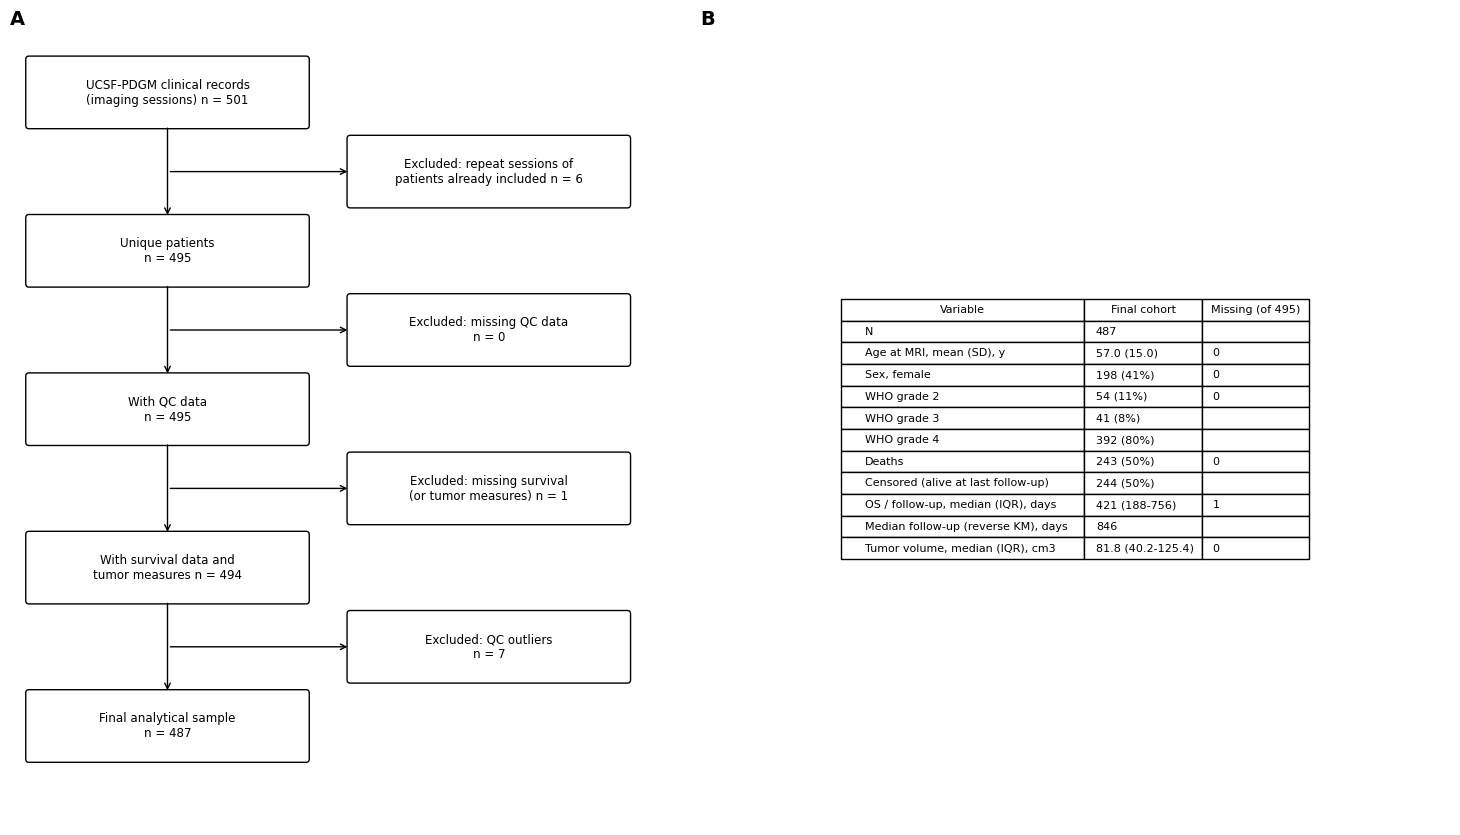

,Variable,Final cohort,Missing (of 495)
0,N,487,
1,"Age at MRI, mean (SD), y",57.0 (15.0),0
2,"Sex, female",198 (41%),0
3,WHO grade 2,54 (11%),0
4,WHO grade 3,41 (8%),
5,WHO grade 4,392 (80%),
6,Deaths,243 (50%),0
7,Censored (alive at last follow-up),244 (50%),
8,"OS / follow-up, median (IQR), days",421 (188-756),1
9,"Median follow-up (reverse KM), days",846,


In [6]:
def characteristics_table(df, pre_df):
    # Participant characteristics for df; 'Missing' counts come from pre_df (the post-QC table before survival exclusions).
    # 'unknown' / 'indeterminate' entries (MGMT, 1p/19q) are counted as missing.
    def miss(col):
        v = pre_df[col]
        return int(v.isna().sum() + v.isin(['unknown', 'indeterminate']).sum())
    pct = lambda n: f'{n} ({100 * n / len(df):.0f}%)'
    fu = KaplanMeierFitter().fit(df['OS'], 1 - df[EVENT_COL])          # reverse Kaplan-Meier = median follow-up
    rows = [('N', f'{len(df)}', ''),
            ('Age at MRI, mean (SD), y', f"{df['Age at MRI'].mean():.1f} ({df['Age at MRI'].std():.1f})", miss('Age at MRI')),
            ('Sex, female', pct(int((df['Sex'] == 'F').sum())), miss('Sex'))]
    for g in sorted(df['WHO CNS Grade'].unique()):
        rows.append((f'WHO grade {int(g)}', pct(int((df['WHO CNS Grade'] == g).sum())), miss('WHO CNS Grade') if g == min(df['WHO CNS Grade']) else ''))
    dx = 'Final pathologic diagnosis (WHO 2021)'
    if TABLE_EXTRA_ROWS and dx in df:
        for name, n in df[dx].value_counts().items():
            rows.append((f'  {name}', pct(int(n)), miss(dx) if name == df[dx].value_counts().index[0] else ''))
    if TABLE_EXTRA_ROWS and 'IDH' in df:
        rows.append(('IDH-mutant (any)', pct(int((df['IDH'] != 'wildtype').sum())), miss('IDH')))
    if TABLE_EXTRA_ROWS and 'MGMT status' in df:
        rows.append(('MGMT promoter methylated', pct(int((df['MGMT status'] == 'positive').sum())), miss('MGMT status')))
    if TABLE_EXTRA_ROWS and 'EOR' in df:
        for name in ['GTR', 'STR', 'biopsy']:
            rows.append((f'Extent of resection: {name}', pct(int((df['EOR'] == name).sum())), miss('EOR') if name == 'GTR' else ''))
    if TABLE_EXTRA_ROWS and 'Biopsy prior to imaging' in df:
        rows.append(('Biopsy prior to imaging', pct(int((df['Biopsy prior to imaging'] == 'Yes').sum())), miss('Biopsy prior to imaging')))
    rows += [('Deaths', pct(int(df[EVENT_COL].sum())), miss(EVENT_COL)),
             ('Censored (alive at last follow-up)', pct(int((df[EVENT_COL] == 0).sum())), ''),
             ('OS / follow-up, median (IQR), days', f"{df['OS'].median():.0f} ({df['OS'].quantile(.25):.0f}-{df['OS'].quantile(.75):.0f})", miss('OS')),
             ('Median follow-up (reverse KM), days', f"{fu.median_survival_time_:.0f}", ''),
             ('Tumor volume, median (IQR), cm3', f"{df['tumor_vol_cm3'].median():.1f} ({df['tumor_vol_cm3'].quantile(.25):.1f}-{df['tumor_vol_cm3'].quantile(.75):.1f})", miss('tumor_vol_cm3'))]
    return pd.DataFrame(rows, columns=['Variable', 'Final cohort', f'Missing (of {len(pre_df)})'])

def draw_flow(ax, f):
    ax.axis('off'); ax.set_xlim(0, 10); ax.set_ylim(0, 12)
    def box(x, y, w, h, text):
        ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05', fc='white', ec='black'))
        ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=8.5)
    def arrow(x1, y1, x2, y2):
        ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->'))
    main = [(f"UCSF-PDGM clinical records\n(imaging sessions) n = {f['original']}"),
            (f"Unique patients\nn = {f['unique_patients']}"),
            (f"With QC data\nn = {f['after_qc']}"),
            (f"With survival data and\ntumor measures n = {f['after_survival']}"),
            (f"Final analytical sample\nn = {f['final']}")]
    side = [(f"Excluded: repeat sessions of\npatients already included n = {f['repeat_sessions']}"),
            (f"Excluded: missing QC data\nn = {f['missing_qc']}"),
            (f"Excluded: missing survival\n(or tumor measures) n = {f['missing_survival_or_metrics']}"),
            (f"Excluded: QC outliers\nn = {f['qc_outliers']}")]
    ys = [10.6, 8.2, 5.8, 3.4, 1.0]
    for y, t in zip(ys, main):
        box(0.3, y, 4.4, 1.0, t)
    for i, t in enumerate(side):
        y_mid = (ys[i] + ys[i + 1] + 1.0) / 2 - 0.5
        box(5.4, y_mid, 4.4, 1.0, t)
        arrow(2.5, ys[i], 2.5, ys[i + 1] + 1.0)
        arrow(2.5, y_mid + 0.5, 5.4, y_mid + 0.5)

fig = plt.figure(figsize=(15, 9))
axA = fig.add_axes([0.02, 0.05, 0.42, 0.88]); draw_flow(axA, flow)
axA.set_title('A', loc='left', fontsize=14, fontweight='bold')
axB = fig.add_axes([0.48, 0.05, 0.50, 0.88]); axB.axis('off')
tbl1 = characteristics_table(primary, base)
t = axB.table(cellText=tbl1.values, colLabels=tbl1.columns, loc='center', cellLoc='left')
t.auto_set_font_size(False); t.set_fontsize(8); t.scale(1, 1.3); t.auto_set_column_width([0, 1, 2])
axB.set_title('B', loc='left', fontsize=14, fontweight='bold')
plt.savefig(os.path.join(SAVE_DIR, 'figure2_flow_and_characteristics.pdf'), bbox_inches='tight')
plt.show()
tbl1.to_csv(os.path.join(SAVE_DIR, 'table1_characteristics.csv'), index=False)
tbl1

## 5. Kaplan–Meier analysis, log-rank tests, Levene's test, and power analysis

In [7]:
Z = stats.norm.ppf

def logrank_power(n_events, prop_group1, hr, alpha=ALPHA):
    """Approximate power of a two-group log-rank test (Schoenfeld). n_events = total events in both groups."""
    effect = abs(np.log(hr)) * np.sqrt(n_events * prop_group1 * (1 - prop_group1))
    return float(stats.norm.cdf(effect - Z(1 - alpha / 2)))

def min_detectable_hr(n_events, prop_group1, alpha=ALPHA, power=0.80):
    """Smallest hazard ratio (>1) detectable with the requested power, given total events (Schoenfeld approximation)."""
    z = Z(1 - alpha / 2) + Z(power)
    return float(np.exp(z / np.sqrt(n_events * prop_group1 * (1 - prop_group1))))

def km_group_summary(df, group_col):
    """n, events, censored, and median OS with 95% CI for each group."""
    out = []
    for g, sub in df.groupby(group_col, observed=True):
        kmf = KaplanMeierFitter().fit(sub['OS'], sub[EVENT_COL])
        ci = median_survival_times(kmf.confidence_interval_)
        out.append({'group': g, 'n': len(sub), 'events': int(sub[EVENT_COL].sum()),
                    'censored': int((sub[EVENT_COL] == 0).sum()),
                    'median_OS_days': kmf.median_survival_time_,
                    'median_CI_low': ci.iloc[0, 0], 'median_CI_high': ci.iloc[0, 1]})
    return pd.DataFrame(out)

def compare_groups(df, group_col):
    """Overall log-rank test, Levene's test, power, and (optionally) Bonferroni-corrected pairwise log-rank tests."""
    lr = multivariate_logrank_test(df['OS'], df[group_col], df[EVENT_COL])
    groups = {g: s for g, s in df.groupby(group_col, observed=True)}
    lev = stats.levene(*[s['OS'].values for s in groups.values()], center='median')
    res = {'overall_logrank_chi2': lr.test_statistic, 'overall_logrank_df': len(groups) - 1,
           'overall_logrank_p': lr.p_value, 'levene_W': lev.statistic, 'levene_p': lev.pvalue}
    pair_rows = []
    keys = list(groups)
    n_pairs = len(list(itertools.combinations(keys, 2)))
    for a, b in itertools.combinations(keys, 2):
        A, B = groups[a], groups[b]
        r = logrank_test(A['OS'], B['OS'], event_observed_A=A[EVENT_COL], event_observed_B=B[EVENT_COL])
        d = int(A[EVENT_COL].sum() + B[EVENT_COL].sum())
        prop = len(A) / (len(A) + len(B))
        a_adj = ALPHA / n_pairs                                # Bonferroni-adjusted alpha for power
        pair_rows.append({'comparison': f'{a} vs {b}', 'n_A': len(A), 'n_B': len(B), 'events_total': d,
                          'logrank_chi2': r.test_statistic, 'p_raw': r.p_value,
                          'p_bonferroni': min(1.0, r.p_value * n_pairs),
                          'min_detectable_HR_80pct_power': min_detectable_hr(d, prop, alpha=a_adj) if d > 0 else np.nan,
                          'power_if_HR_1.5': logrank_power(d, prop, 1.5, alpha=a_adj) if d > 0 else np.nan,
                          'power_if_HR_2.0': logrank_power(d, prop, 2.0, alpha=a_adj) if d > 0 else np.nan})
    return res, pd.DataFrame(pair_rows)

continuous_vars = {'Age at MRI': 'Age', 'tumor_vol_cm3': 'Tumor volume', 'centroid_x': 'Centroid X',
                   'centroid_y': 'Centroid Y', 'centroid_z': 'Centroid Z'}

def run_survival(df, label):
    print('=' * 80); print(label, f'(n = {len(df)})'); print('=' * 80)
    df = df.copy()
    summaries, comparisons = [], []

    # categorical variables: WHO grade (pairwise, Bonferroni), sex
    for col, pw in [('WHO CNS Grade', True), ('Sex', False)]:
        s = km_group_summary(df, col); s.insert(0, 'variable', col); summaries.append(s)
        res, pairs = compare_groups(df, col)
        res['variable'] = col; comparisons.append(res)
        print(f'\n{col}'); print(s.round(1).to_string(index=False))
        print(f"  log-rank chi2 = {res['overall_logrank_chi2']:.2f}, df = {res['overall_logrank_df']}, p = {res['overall_logrank_p']:.3g}"
              f" | Levene W = {res['levene_W']:.2f}, p = {res['levene_p']:.3g}")
        print(pairs.round(4).to_string(index=False))
        if col == 'WHO CNS Grade':
            grade_pairs = pairs

    # continuous variables: median split (High vs Low), same tests
    for col, nice in continuous_vars.items():
        df[f'{col}_grp'] = np.where(df[col] >= df[col].median(), 'High (>= median)', 'Low (< median)')
        s = km_group_summary(df, f'{col}_grp'); s.insert(0, 'variable', nice); summaries.append(s)
        res, pairs = compare_groups(df, f'{col}_grp')
        res['variable'] = nice
        res['min_detectable_HR_80pct_power'] = pairs['min_detectable_HR_80pct_power'].iloc[0]
        res['power_if_HR_1.5'] = pairs['power_if_HR_1.5'].iloc[0]
        res['power_if_HR_2.0'] = pairs['power_if_HR_2.0'].iloc[0]
        comparisons.append(res)
        print(f"\n{nice} (median split): log-rank chi2 = {res['overall_logrank_chi2']:.2f}, p = {res['overall_logrank_p']:.3g}; "
              f"Levene p = {res['levene_p']:.3g}; min detectable HR (80% power) = {res['min_detectable_HR_80pct_power']:.2f}")

    summary_df = pd.concat(summaries, ignore_index=True)
    comp_df = pd.DataFrame(comparisons)
    return summary_df, comp_df, grade_pairs

results = {}
for label, d in cohorts.items():
    results[label] = run_survival(d, label)
    tag = label.split(' (')[0].replace(' ', '_')
    results[label][0].to_csv(os.path.join(SAVE_DIR, f'km_summary_{tag}.csv'), index=False)
    results[label][1].to_csv(os.path.join(SAVE_DIR, f'logrank_levene_power_{tag}.csv'), index=False)
    results[label][2].to_csv(os.path.join(SAVE_DIR, f'grade_pairwise_{tag}.csv'), index=False)

# Sensitivity comparison: do the exclusions change the log-rank conclusions?
sens = pd.concat([r[1].assign(cohort=k)[['cohort', 'variable', 'overall_logrank_chi2', 'overall_logrank_p', 'levene_p']]
                  for k, r in results.items()])
print('\nSensitivity comparison (log-rank p by cohort)')
print(sens.pivot(index='variable', columns='cohort', values='overall_logrank_p').round(4).to_string())
sens.to_csv(os.path.join(SAVE_DIR, 'sensitivity_comparison.csv'), index=False)

Primary (QC outliers excluded) (n = 487)

WHO CNS Grade
     variable  group   n  events  censored  median_OS_days  median_CI_low  median_CI_high
WHO CNS Grade      2  54       8        46          2191.0         1612.0          2191.0
WHO CNS Grade      3  41      10        31             inf          998.0             inf
WHO CNS Grade      4 392     225       167           545.0          472.0           628.0
  log-rank chi2 = 62.33, df = 2, p = 2.92e-14 | Levene W = 13.08, p = 2.95e-06
comparison  n_A  n_B  events_total  logrank_chi2  p_raw  p_bonferroni  min_detectable_HR_80pct_power  power_if_HR_1.5  power_if_HR_2.0
    2 vs 3   54   41            18        1.8015 0.1795        0.5386                         4.6635           0.0615           0.1743
    2 vs 4   54  392           233       43.5155 0.0000        0.0000                         1.9151           0.3538           0.8549
    3 vs 4   41  392           235       21.7216 0.0000        0.0000                         2.0563

### Supplementary Kaplan–Meier figures (primary cohort; individual plots with numbers-at-risk tables)

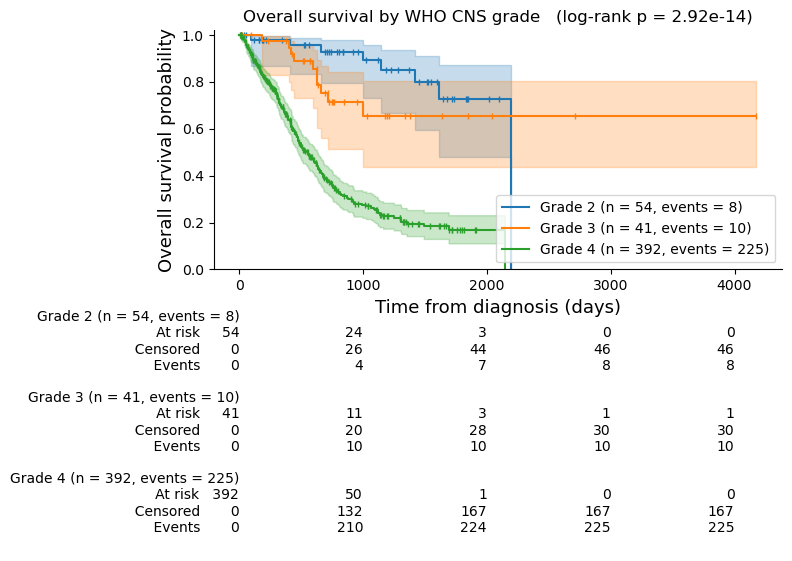

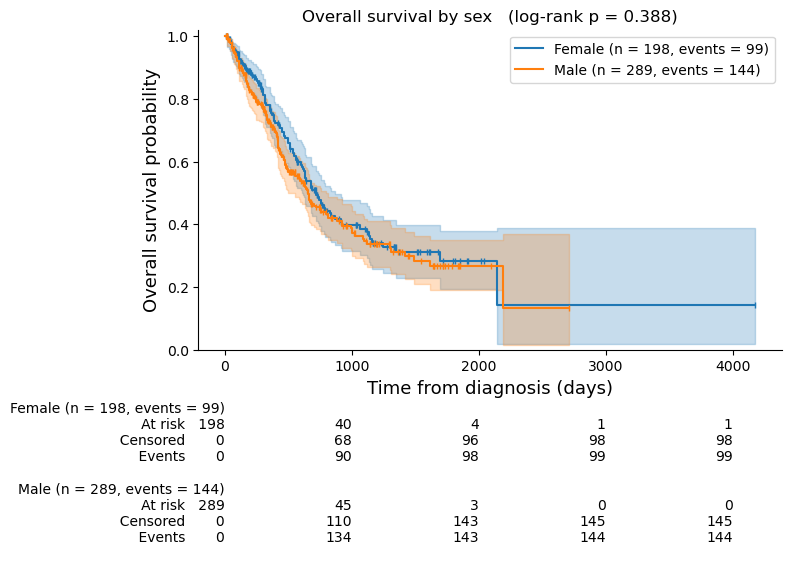

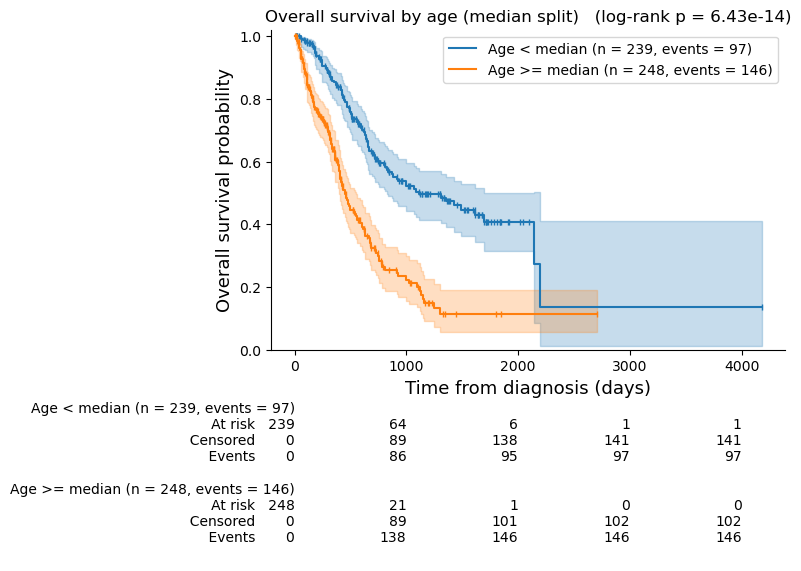

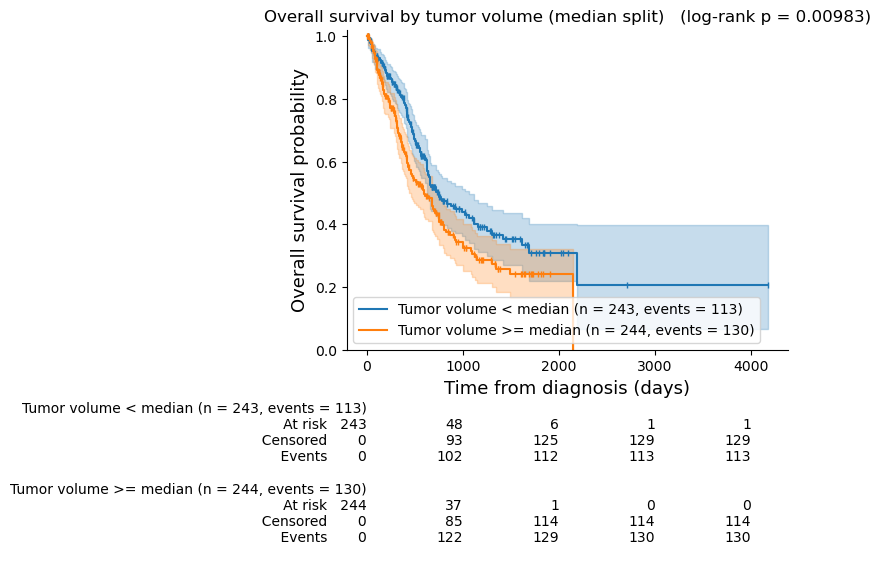

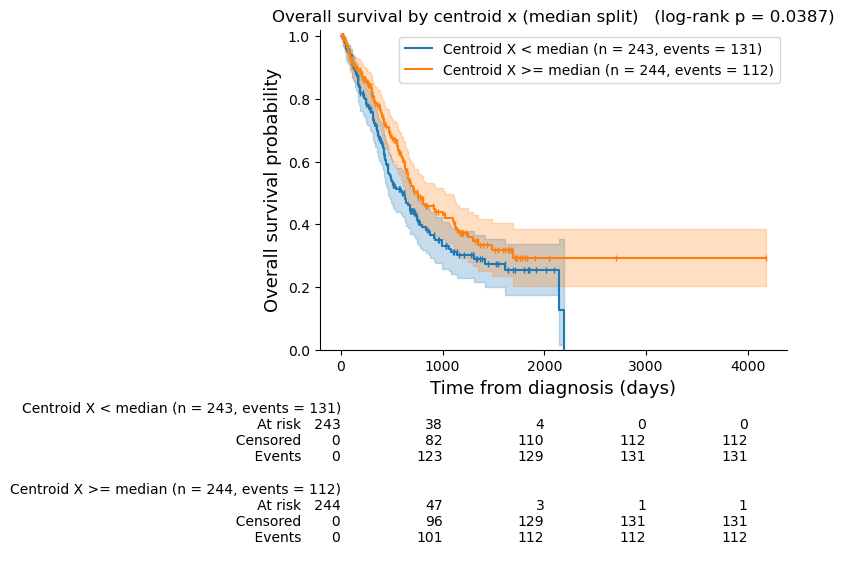

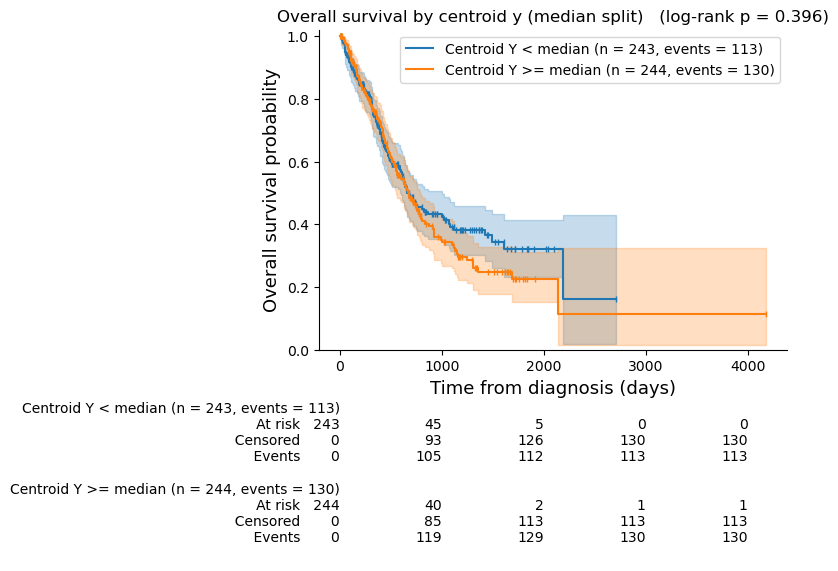

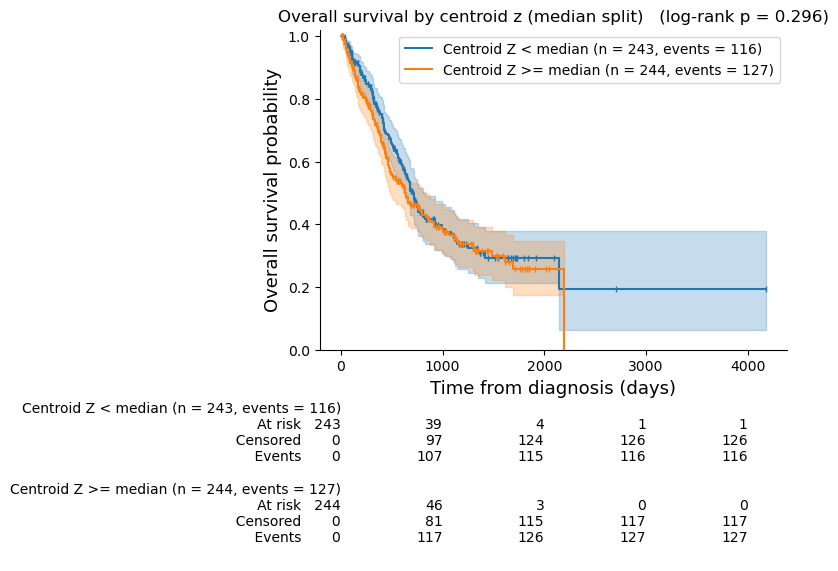

In [8]:
def km_plot(df, group_col, order, labels, title, fname):
    fig, ax = plt.subplots(figsize=(8, 6))
    fitters = []
    for g in order:
        sub = df[df[group_col] == g]
        kmf = KaplanMeierFitter()
        kmf.fit(sub['OS'], sub[EVENT_COL], label=f'{labels[g]} (n = {len(sub)}, events = {int(sub[EVENT_COL].sum())})')
        kmf.plot_survival_function(ax=ax, ci_show=True, show_censors=True, censor_styles={'ms': 4, 'marker': '|'})
        fitters.append(kmf)
    p = multivariate_logrank_test(df['OS'], df[group_col], df[EVENT_COL]).p_value
    ax.set_title(f'{title}   (log-rank p = {p:.3g})', fontsize=12)
    ax.set_xlabel('Time from diagnosis (days)', size=13)
    ax.set_ylabel('Overall survival probability', size=13)
    ax.set_ylim(0, 1.02)
    sns.despine(ax=ax)
    add_at_risk_counts(*fitters, ax=ax)
    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, fname), bbox_inches='tight')
    plt.show()

prim = cohorts['Primary (QC outliers excluded)']
grades = sorted(prim['WHO CNS Grade'].unique())
km_plot(prim, 'WHO CNS Grade', grades, {g: f'Grade {int(g)}' for g in grades}, 'Overall survival by WHO CNS grade', 'km_grade.pdf')
km_plot(prim, 'Sex', ['F', 'M'], {'F': 'Female', 'M': 'Male'}, 'Overall survival by sex', 'km_sex.pdf')
for col, nice in continuous_vars.items():
    p2 = prim.copy()
    p2['grp'] = np.where(p2[col] >= p2[col].median(), 'High', 'Low')
    km_plot(p2, 'grp', ['Low', 'High'], {'Low': f'{nice} < median', 'High': f'{nice} >= median'},
            f'Overall survival by {nice.lower()} (median split)', f'km_{col}.pdf')

## 6. Lasso on all variables combined
All predictors enter one model (age, sex, WHO grade as categorical, tumor volume, centroid x/y/z); there is **no univariable screening**.
Scaling (predictors and OS) and the Lasso penalty are fit **inside each training fold** (outer repeated 5-fold CV; inner 5-fold CV tunes alpha).
Note: OS in days is modeled as a continuous outcome here, so censoring is not modeled by the Lasso; the Kaplan–Meier analysis above is the primary survival analysis.

Lasso - Primary (QC outliers excluded) (n = 487)
  alpha (full-data fit, standardized OS): 0.0129
  Cross-validated R2: mean = 0.172, SD = 0.075, 2.5-97.5th pct = 0.021 to 0.286
  Nonzero coefficients: 8 / 10
              feature  coefficient
cat__WHO CNS Grade_G4      -0.4069
      num__Age at MRI      -0.3690
           cat__Sex_F       0.1192
      num__centroid_y       0.1015
      num__centroid_x       0.0268
   num__tumor_vol_cm3      -0.0190
      num__centroid_z       0.0008
           cat__Sex_M      -0.0000
cat__WHO CNS Grade_G2       0.0000
cat__WHO CNS Grade_G3       0.0000
Lasso - Sensitivity (QC outliers included) (n = 494)
  alpha (full-data fit, standardized OS): 0.0149
  Cross-validated R2: mean = 0.182, SD = 0.073, 2.5-97.5th pct = 0.030 to 0.292
  Nonzero coefficients: 7 / 10
              feature  coefficient
cat__WHO CNS Grade_G4      -0.3848
      num__Age at MRI      -0.3687
           cat__Sex_F       0.1285
      num__centroid_y       0.0982
      num__centroi

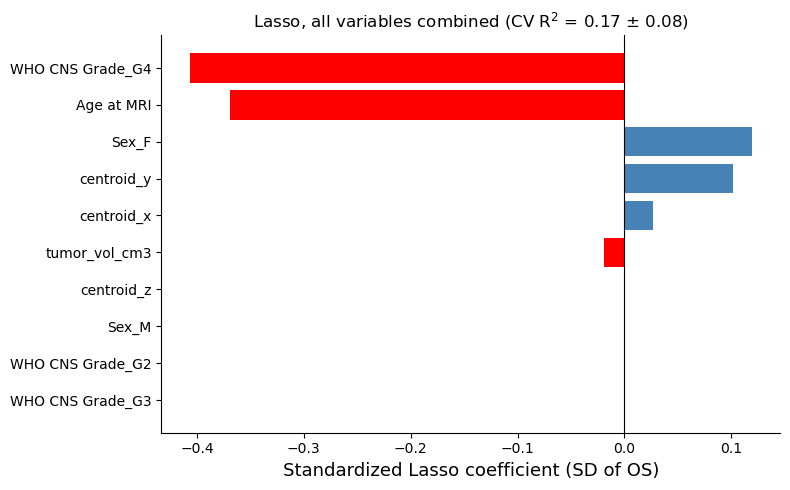

In [9]:
num_cols = ['Age at MRI', 'tumor_vol_cm3', 'centroid_x', 'centroid_y', 'centroid_z']
cat_cols = ['Sex', 'WHO CNS Grade']
if USE_EXTRA_COVARIATES:
    cat_cols += ['IDH', 'MGMT status', 'EOR', 'Biopsy prior to imaging']    # missing values kept as their own category

def make_model():
    prep = ColumnTransformer([('num', StandardScaler(), num_cols),
                              ('cat', OneHotEncoder(), cat_cols)])
    inner = Pipeline([('prep', prep),
                      ('lasso', LassoCV(cv=5, max_iter=20000, random_state=RANDOM_SEED))])
    # TransformedTargetRegressor standardizes OS within each training fold
    return TransformedTargetRegressor(regressor=inner, transformer=StandardScaler())

def run_lasso(df, label):
    X = df[num_cols + cat_cols].copy()
    X['WHO CNS Grade'] = 'G' + X['WHO CNS Grade'].astype(int).astype(str)   # grade as categorical
    for c in cat_cols:
        if c not in ('Sex', 'WHO CNS Grade'):
            X[c] = X[c].fillna('missing').astype(str)
    y = df['OS'].values
    model = make_model()
    cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_SEED)
    scores = cross_val_score(model, X, y, cv=cv, scoring='r2')
    model.fit(X, y)
    pipe = model.regressor_
    names = pipe.named_steps['prep'].get_feature_names_out()
    coefs = pipe.named_steps['lasso'].coef_
    print('=' * 80); print(f'Lasso - {label} (n = {len(df)})')
    print(f"  alpha (full-data fit, standardized OS): {pipe.named_steps['lasso'].alpha_:.4f}")
    print(f'  Cross-validated R2: mean = {scores.mean():.3f}, SD = {scores.std():.3f}, '
          f'2.5-97.5th pct = {np.percentile(scores, 2.5):.3f} to {np.percentile(scores, 97.5):.3f}')
    print(f'  Nonzero coefficients: {(coefs != 0).sum()} / {len(coefs)}')
    coef_df = pd.DataFrame({'feature': names, 'coefficient': coefs}).sort_values('coefficient', key=abs, ascending=False)
    print(coef_df.round(4).to_string(index=False))
    return coef_df, scores

lasso_results = {}
for label, d in cohorts.items():
    lasso_results[label] = run_lasso(d, label)
    tag = label.split(' (')[0].replace(' ', '_')
    lasso_results[label][0].to_csv(os.path.join(SAVE_DIR, f'lasso_coefficients_{tag}.csv'), index=False)

# Coefficient figure (primary cohort). Coefficients are in SD of OS per SD of the predictor (dummy variables: per category).
coef_df, scores = lasso_results['Primary (QC outliers excluded)']
fig, ax = plt.subplots(figsize=(8, 5))
cdf = coef_df.iloc[::-1]
ax.barh(cdf['feature'].str.replace('num__', '').str.replace('cat__', ''), cdf['coefficient'],
        color=['red' if c < 0 else 'steelblue' for c in cdf['coefficient']])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Standardized Lasso coefficient (SD of OS)', size=13)
ax.set_title(f'Lasso, all variables combined (CV R$^2$ = {scores.mean():.2f} $\\pm$ {scores.std():.2f})', fontsize=12)
sns.despine(ax=ax); plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'lasso_coefficients.pdf'), bbox_inches='tight')
plt.show()

## 7. Figure 1 — combined results figure (primary cohort)
Combines the two original figures into one four-panel figure, redrawn with the corrected analyses:
(a) Kaplan–Meier curves by WHO CNS grade (replaces the violin plots), (b) Kaplan–Meier curves by age (median split), (c) Kaplan–Meier curves by tumor volume (median split),
(d) Lasso coefficients for all variables combined (replaces the original Figure 2).

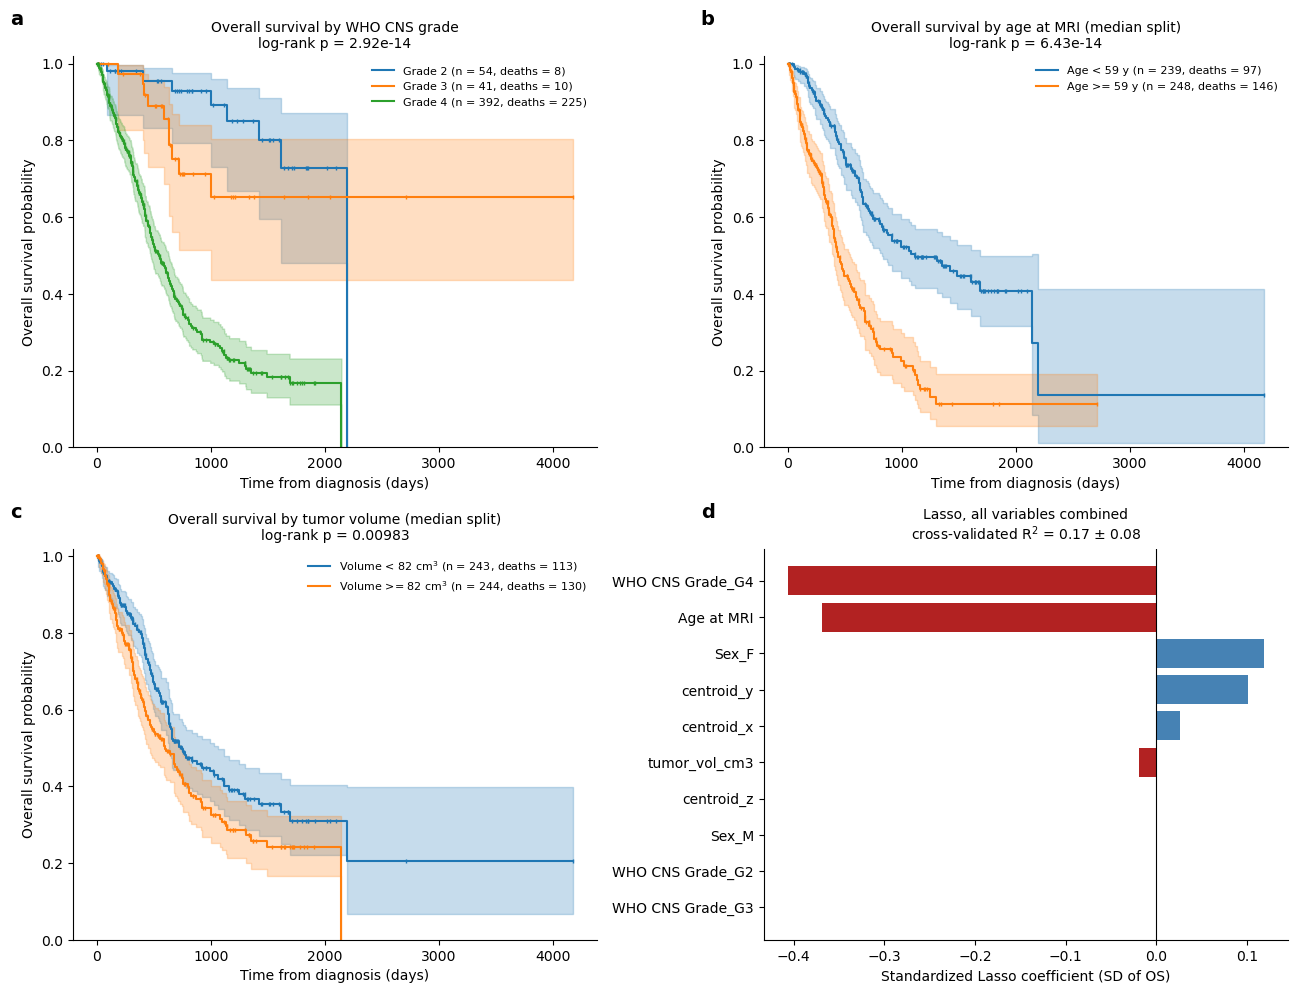

In [10]:
def km_panel(ax, df, group_col, order, labels, title):
    for g in order:
        sub = df[df[group_col] == g]
        kmf = KaplanMeierFitter()
        kmf.fit(sub['OS'], sub[EVENT_COL], label=f'{labels[g]} (n = {len(sub)}, deaths = {int(sub[EVENT_COL].sum())})')
        kmf.plot_survival_function(ax=ax, ci_show=True, show_censors=True, censor_styles={'ms': 3, 'marker': '|'})
    p = multivariate_logrank_test(df['OS'], df[group_col], df[EVENT_COL]).p_value
    ax.set_title(f'{title}\nlog-rank p = {p:.3g}', fontsize=10)
    ax.set_xlabel('Time from diagnosis (days)', size=10)
    ax.set_ylabel('Overall survival probability', size=10)
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=8, loc='upper right', frameon=False)
    sns.despine(ax=ax)

prim = cohorts['Primary (QC outliers excluded)'].copy()
grades = sorted(prim['WHO CNS Grade'].unique())
prim['age_grp'] = np.where(prim['Age at MRI'] >= prim['Age at MRI'].median(), 'High', 'Low')
prim['vol_grp'] = np.where(prim['tumor_vol_cm3'] >= prim['tumor_vol_cm3'].median(), 'High', 'Low')

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
km_panel(axes[0, 0], prim, 'WHO CNS Grade', grades, {g: f'Grade {int(g)}' for g in grades}, 'Overall survival by WHO CNS grade')
km_panel(axes[0, 1], prim, 'age_grp', ['Low', 'High'],
         {'Low': f"Age < {prim['Age at MRI'].median():.0f} y", 'High': f"Age >= {prim['Age at MRI'].median():.0f} y"}, 'Overall survival by age at MRI (median split)')
km_panel(axes[1, 0], prim, 'vol_grp', ['Low', 'High'],
         {'Low': f"Volume < {prim['tumor_vol_cm3'].median():.0f} cm$^3$", 'High': f"Volume >= {prim['tumor_vol_cm3'].median():.0f} cm$^3$"}, 'Overall survival by tumor volume (median split)')

coef_df, scores = lasso_results['Primary (QC outliers excluded)']
ax = axes[1, 1]
cdf = coef_df.iloc[::-1]
ax.barh(cdf['feature'].str.replace('num__', '').str.replace('cat__', ''), cdf['coefficient'],
        color=['firebrick' if c < 0 else 'steelblue' for c in cdf['coefficient']])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Standardized Lasso coefficient (SD of OS)', size=10)
ax.set_title(f'Lasso, all variables combined\ncross-validated R$^2$ = {scores.mean():.2f} $\\pm$ {scores.std():.2f}', fontsize=10)
sns.despine(ax=ax)

for lab, a in zip('abcd', axes.flat):
    a.text(-0.12, 1.08, lab, transform=a.transAxes, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'figure1_combined_results.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(SAVE_DIR, 'figure1_combined_results.png'), dpi=300, bbox_inches='tight')
plt.show()

In [11]:
ndc_cols = [c for c in qc.columns if 'neighbor' in c.lower() or 'ndc' in c.lower()]
print('QC columns:', list(qc.columns))
print('NDC-like columns:', ndc_cols)
for c in ndc_cols:
    flagged = qc.loc[qc['outlier'] == 1, c]
    others = qc.loc[qc['outlier'] != 1, c]
    print(f"{c}: flagged n={len(flagged)}, min={flagged.min():.3f}, max={flagged.max():.3f} | "
          f"others median={others.median():.3f} (IQR {others.quantile(.25):.3f}-{others.quantile(.75):.3f})")

QC columns: ['file name', 'dimension', 'resolution', 'dwi count(b0/dwi)', 'max b-value', 'DWI contrast', 'neighboring DWI correlation', 'neighboring DWI correlation(masked)', '#bad slices', 'outlier', 'ID']
NDC-like columns: ['neighboring DWI correlation', 'neighboring DWI correlation(masked)']
neighboring DWI correlation: flagged n=7, min=0.912, max=0.937 | others median=0.966 (IQR 0.952-0.970)
neighboring DWI correlation(masked): flagged n=7, min=0.582, max=0.645 | others median=0.802 (IQR 0.759-0.829)


In [12]:
vals = {}
for p in seg_files:
    u, c = np.unique(nib.load(p).get_fdata().astype(int), return_counts=True)
    for k in u: vals[k] = vals.get(k, 0) + 1
print('Label values found, and number of files containing each:', vals)

Label values found, and number of files containing each: {np.int64(0): 495, np.int64(1): 395, np.int64(2): 495, np.int64(4): 420}


In [13]:
s = results['Primary (QC outliers excluded)'][0]
cont = s[s['variable'].isin(['Age', 'Tumor volume', 'Centroid X', 'Centroid Y', 'Centroid Z'])].copy()
fmt = lambda v: 'NR' if not np.isfinite(v) else f'{v:.0f}'
cont['Median OS, days (95% CI)'] = cont.apply(
    lambda r: f"{fmt(r.median_OS_days)} ({fmt(r.median_CI_low)}\u2013{fmt(r.median_CI_high)})", axis=1)
print(cont[['variable', 'group', 'n', 'events', 'Median OS, days (95% CI)']].to_string(index=False))

    variable            group   n  events Median OS, days (95% CI)
         Age High (>= median) 248     146            446 (396–545)
         Age   Low (< median) 239      97          1116 (824–1690)
Tumor volume High (>= median) 244     130            599 (446–749)
Tumor volume   Low (< median) 243     113           743 (633–1067)
  Centroid X High (>= median) 244     112           753 (635–1024)
  Centroid X   Low (< median) 243     131            624 (465–743)
  Centroid Y High (>= median) 244     130            676 (554–785)
  Centroid Y   Low (< median) 243     113            663 (591–998)
  Centroid Z High (>= median) 244     127            629 (484–837)
  Centroid Z   Low (< median) 243     116            716 (611–809)


In [14]:
cols = ['ID', 'Sex', 'Age at MRI', 'WHO CNS Grade', 'OS', EVENT_COL,
        'tumor_vol_cm3', 'centroid_x', 'centroid_y', 'centroid_z']
ds = with_surv[cols].copy()
ds['qc_outlier'] = ds['ID'].isin(outlier_ids).astype(int)
ds.to_csv(os.path.join(SAVE_DIR, 'analytical_dataset.csv'), index=False)
print(ds.shape, ds['qc_outlier'].sum())

(494, 11) 7
